# Leaf traits inversion

In this tutorial, you will get hands on **PROSPECT, a model of leaf optical properties**:<br>
* [1] *Féret, J. B., Gitelson, A. A., Noble, S. D., & Jacquemoud, S. J. R. S. O. E. (2017). PROSPECT-D: Towards modeling leaf optical properties through a complete lifecycle. Remote Sensing of Environment, 193, 204-215.* 
* [2] *Jacquemoud, S., & Baret, F. (1990). PROSPECT: A model of leaf optical properties spectra. Remote sensing of environment, 34(2), 75-91.*

<center>
    <img src="prospect.png" width=700>

    HIgh-level illustration of PROSPECT for forward and inverse modeling. Credit: Jean-Baptiste Féret.
</center>

<br>

You will use PROSPECT to estimate leaf traits from Sentinel-2 images. We call leaf traits the physical, biological, and chemical properties of the leaves. In particular, "three main families of pigments are found in leaves: **chlorophylls, carotenoids, and anthocyanins**" [1]. The dynamics of those pigments "directly affects nutrient, nitrogen, carbon and water cycles (Shipley et al., 2006; Joiner et al., 2011)", making them "**good indicators of changes in environmental conditions** from local to global scales." [1]

#### PROSPECT model: From bio-physical properties to optical properties

The PROSPECT model "assumes that **leaves are composed of N homogeneous plate layers separated by N-1 air layers**". "By inputting different parameters and corresponding **spectral absorption coefficients of leaf biochemical constituents** such as the content of chlorophyll, water, and dry matter, the **hemispherical reflectance and transmittance** of plant leaves across the 400–2500 nm wavelength range can be simulated." [3]

<center>
    <img src="prospect_model.jpg" width=500>
    
    Illustration of the PROSPECT model [1, 2]. Figure reproduced from [3]. 
</center>

<br>

**The model is calibrated and validated against paired measurements of leaf optics and leaf biochemistry.** In particular, the specific absorption coefficients of chlorophylls, carotenoids, and anthocyanins used by the PROSPECT model are plotted below:

<center>
    <img src="sacs_feret.png" width=500>
    
    Specific absorption coefficients (SAC) of chlorophylls (green), carotenoids (orange), and anthocyanins (red). The solids line correspond to the SAC of all the pigments in PROSPECT-D, the dashed lines to the SAC of chlorophylls and carotenoids in PROSPECT-5, and to the SAC of anthocyanins measured by Peters and Noble (2014) using thin layer chromatography. Figure and caption reproduced from [1]. 
</center>

<br> 

The total absorption is the sum of the concentrations of each constituent (chlorophylls, carotenoids, anthocyanins, water/brown pigments, dry matter) times their specific absorption coefficients.

[3] *Yu, F., Xiang, S., Jin, Z., Bai, J., & Xu, T. (2026). Advancements in Leaf-Scale Radiative Transfer Modeling: A Review with Focus on the PROSPECT Model. Agriculture Communications, 100122.*

## Forward modeling

First, we will use a Python interface to run the PROSPECT model: https://github.com/jgomezdans/prosail/tree/master

In [14]:
import os
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import prosail

sys.path.append('../basics_radiative_transfer_modeling')

from utils.utils import plot_dict

Below, we define for each leaf parameter the default value and intervals commonly used in the literature. 

In [2]:
LEAF_TRAITS = {
    'N': {'desc': 'Leaf structure parameter', 'range': [1.0, 2.5], 'default': 1.5, 'unit': None},
    'Cab': {'desc': 'Chlorophyll a+b concentration', 'range': [20, 80], 'default': 40, 'unit': 'µg/cm²'},
    'Car': {'desc': 'Cartenoid concentration', 'range': [3, 15], 'default': 8, 'unit': 'µg/cm²'},
    'Cbrown': {'desc': 'Brown pigment', 'range': [0, 1], 'default': 0, 'unit': None},
    'Cw': {'desc': 'Equivalent water thickness', 'range': [0.005, 0.04], 'default': 0.015, 'unit': 'cm'},
    'Cm': {'desc': 'Dry matter', 'range': [0.002, 0.02], 'default': 0.009, 'unit': 'g/cm²'}
}

Use PROSPECT to simulate reflectance spectra from 0.4 µm to 2.5 µm for varying values of leaf traits. See https://github.com/jgomezdans/prosail/blob/master/prosail/prospect_d.py on how to call the PROSPECT-D model.

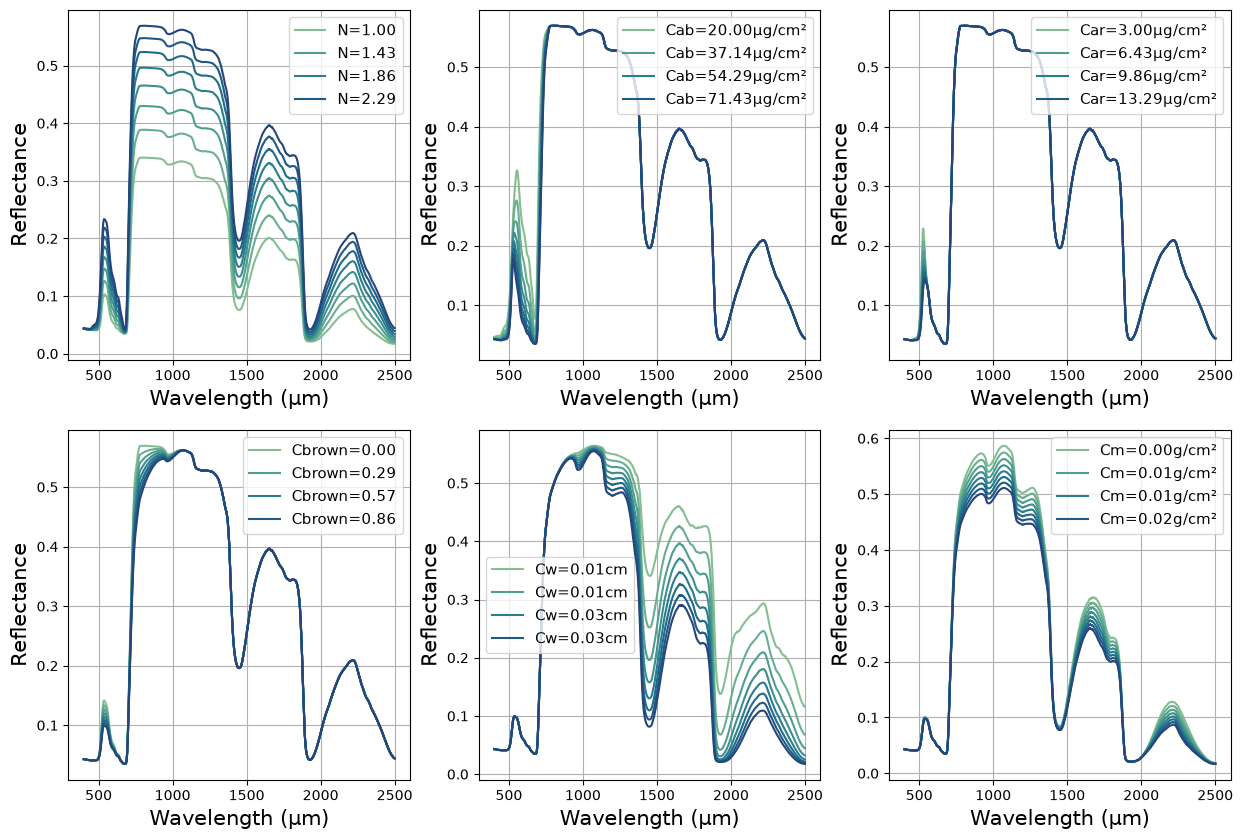

In [3]:
n_values = 8
fontsize = 15

colors = sns.color_palette("crest", n_values)
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
# <CORRECTION>
for trait, ax in zip(LEAF_TRAITS, axs.flat):
    range_trait = LEAF_TRAITS[trait]['range']
    trait_values = np.linspace(range_trait[0], range_trait[1], n_values)
    for i, trait_value in enumerate(trait_values):
        traits[trait] = trait_value
        lam, rho, tau = prosail.run_prospect(traits['N'], traits['Cab'], traits['Car'], traits['Cbrown'], traits['Cw'], traits['Cm'])
        unit = LEAF_TRAITS[trait]['unit'] if LEAF_TRAITS[trait]['unit'] is not None else ''
        label = f'{trait}={trait_value:.2f}{unit}' if i % 2 == 0 else None
        ax.plot(lam, rho, color=colors[i], label=label)
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
# </CORRECTION>
plt.show()

## Inverse modeling

Now, we will invert the PROSPECT model to estimate leaf traits from reflectance spectra. There are many methods to invert a forward model. Here, we will use methods based on Look-Up Tables (LUT).


#### Look-up Tables

In our context, LUTs are data bases generated by forward models (here the PROSPECT model) for a very large amount of input parameters. LUTs are usually pre-computed because the forward modeling can be time expensive. "Lookup tables (LUTs) are an excellent technique for optimizing the evaluation of functions that are expensive to compute and inexpensive to cache. ... For data requests that fall between the table's samples, an interpolation algorithm can generate reasonable approximations by averaging nearby samples." [NVIDIA article](https://developer.nvidia.com/gpugems/gpugems2/part-iii-high-quality-rendering/chapter-24-using-lookup-tables-accelerate-color)


Then, the inversion of the model, given a reflectance spectrum, simply consists in retrieving the leaf traits that correspond to the most similar spectrum in the LUT.

Let us implement a function `leaf_traits_table` that computes an array of leaf traits by uniformly sampling within the specified intervals, and a function `compute_LUT` that runs the forward model given the array of leaf traits.

In [4]:
def leaf_traits_table(
    variables: List,
    n_values: int,
):
    """ Uniformly sample leaf traits given intervals.
    
    Args:
        variables: list of leaf traits
        n_values : size of the range for every traits

    Returns:
        a np.ndarray of size n_values**(len(variables)) x len(variables)
    """
    # <CORRRECTION>
    trait_ranges = []
    for i, trait in enumerate(LEAF_TRAITS):
        range_trait = LEAF_TRAITS[trait]['range']
        trait_values = np.linspace(range_trait[0], range_trait[1], n_values)
        shape = [1] * len(variables)
        shape[i] = n_values
        final_shape = (n_values,) * len(variables)
        trait_ranges.append(np.broadcast_to(trait_values.reshape(shape), final_shape))
    trait_ranges = np.stack(trait_ranges) #shape = (len(variables),) + (n_values,) * len(variables)
    traits_table = trait_ranges.reshape(len(variables), -1).T
    # </CORRRECTION>
    return traits_table
    
def compute_LUT(
    variables: List,
    n_values: int,
    n_bands: int = 351
):
    """ Computes a Look-Up Table.
    
    Args:
        variables: list of leaf traits
        n_values : size of the range for every traits
        n_bands: number of spectral channels.

    Returns:
        a tuple (traits_table, reflectance_table) containing arrays 
        of size n_values**(len(variables)) x len(variables) and 
        n_values**(len(variables)) x n_bands, respectively.
    """
    # <CORRECTION>
    size = n_values**len(variables)
    reflectance_table = np.zeros((size, n_bands))
    traits_table = leaf_traits_table(variables, n_values)
    for i in range(size):
        _, rho, _ = prosail.run_prospect(
            traits_table[i, 0],
            traits_table[i, 1],
            traits_table[i, 2],
            traits_table[i, 3],
            traits_table[i, 4],
            traits_table[i, 5],
        )
        reflectance_table[i] = rho[::6]
    # </CORRECTION>
    return traits_table, reflectance_table

In [5]:
traits = list(LEAF_TRAITS.keys())
traits_table, reflectance_table = compute_LUT(traits, n_values=6)

Let's model a new reflectance spectrum, and estimate its leaf traits.

In [6]:
import random

new_traits = dict((k, random.uniform(v['range'][0], v['range'][1])) for (k, v) in LEAF_TRAITS.items())
new_traits = [
    new_traits['N'], 
    new_traits['Cab'], 
    new_traits['Car'], 
    new_traits['Cbrown'], 
    new_traits['Cw'], 
    new_traits['Cm']
]

lam, rho, _ = prosail.run_prospect(*new_traits)

lam, rho = lam[::6], rho[::6]

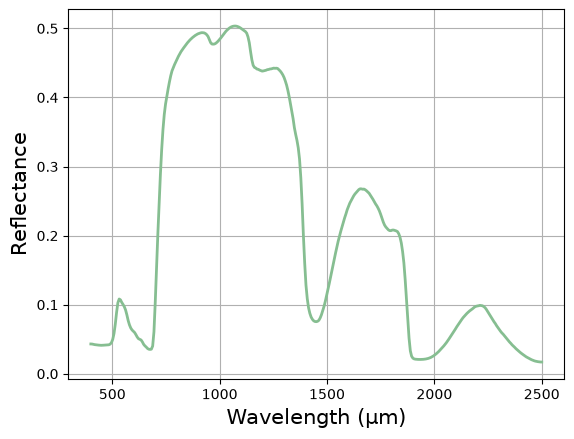

In [7]:
fig, ax = plt.subplots()
ax.plot(lam, rho, color=colors[0], label=label, lw=2)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.grid()
plt.show()

In [8]:
def spectral_distance(spectrum: np.ndarray, spectra: np.ndarray) -> np.ndarray:
    """Computes the euclidean distance between a spectrum and spectra.

    Args:
        spectrum: an array of size n_bands
        spectra: an array of size n_samples x n_bands

    Returns:
        an array of size n_samples
    """
    # <CORRECTION>
    spectrum = spectrum.reshape(1, -1)
    dist = np.sqrt(np.sum((spectrum - spectra)**2, axis=-1))
    return dist
    # </CORRECTION>

dist = spectral_distance(rho, reflectance_table)
closest_spectra_indices = np.argsort(dist)
# closest_spectra_top_3 =
closest_spectra_top_3 = reflectance_table[closest_spectra_indices[:3]]

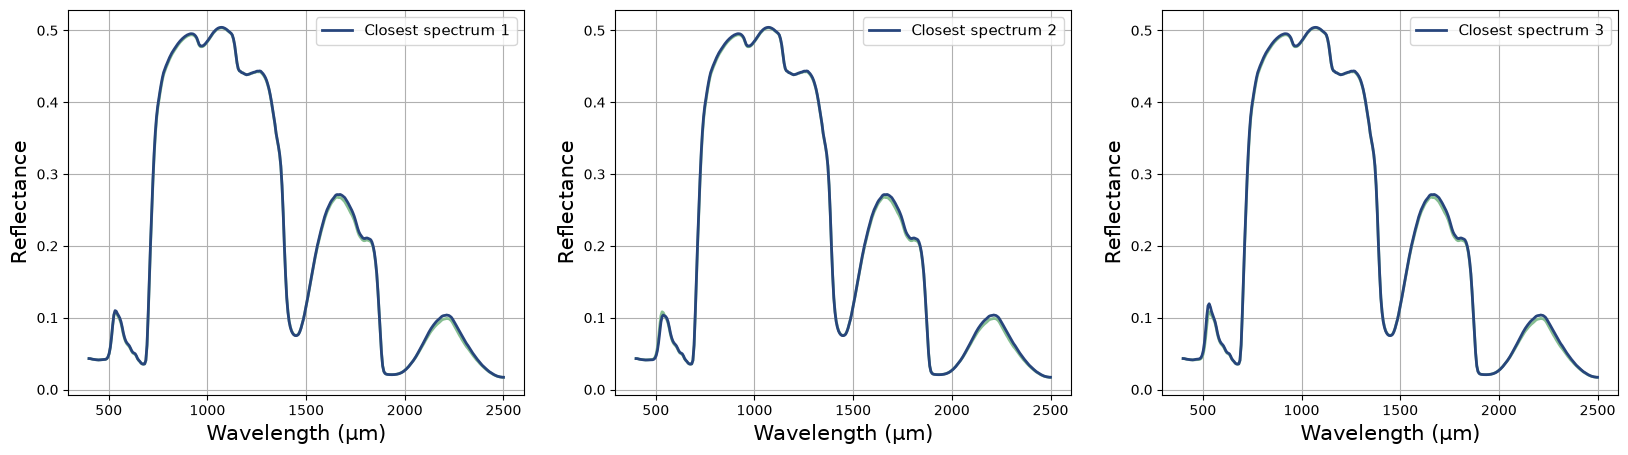

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i, ax in enumerate(axs.flat):
    ax.plot(lam, rho, color=colors[0], lw=2)
    ax.plot(lam, closest_spectra_top_3[i], color=colors[-1], lw=2, label=f'Closest spectrum {i+1}')
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
plt.show()

In [10]:
closest_leaf_traits = traits_table[closest_spectra_indices[:3]]
error = closest_leaf_traits - np.array(new_traits).reshape(1, -1)
abs_error = np.abs(error)
relative_error = error / np.array(new_traits).reshape(1, -1) * 100

error_dict = {}
for i, trait in enumerate(LEAF_TRAITS):
    unit = LEAF_TRAITS[trait]['unit'] if LEAF_TRAITS[trait]['unit'] is not None else ''
    error_dict[trait] = [f"{abs_error[j, i]:.2e}{unit}" for j in range(abs_error.shape[0])]

relative_error_dict = {} 
for i, trait in enumerate(LEAF_TRAITS):
    relative_error_dict[trait] = [f"{relative_error[j, i]:.2f}%" for j in range(abs_error.shape[0])]

In [11]:
plot_dict(error_dict, columns=["Leaf trait", "Absolute Error"], print_type=False)

,Absolute Error
Leaf trait,
N,"['8.94e-02', '8.94e-02', '8.94e-02']"
Cab,"['3.87e+00µg/cm²', '3.87e+00µg/cm²', '3.87e+00..."
Car,"['2.24e-01µg/cm²', '2.18e+00µg/cm²', '2.62e+00..."
Cbrown,"['5.59e-02', '5.59e-02', '5.59e-02']"
Cw,"['9.33e-04cm', '9.33e-04cm', '9.33e-04cm']"
Cm,"['2.80e-03g/cm²', '2.80e-03g/cm²', '2.80e-03g/..."


In [12]:
plot_dict(relative_error_dict, columns=["Leaf trait", "Relative Error"], print_type=False)

,Relative Error
Leaf trait,
N,"['-4.49%', '-4.49%', '-4.49%']"
Cab,"['-6.47%', '-6.47%', '-6.47%']"
Car,"['-2.79%', '27.11%', '-32.70%']"
Cbrown,"['-6.53%', '-6.53%', '-6.53%']"
Cw,"['-2.75%', '-2.75%', '-2.75%']"
Cm,"['-33.37%', '-33.37%', '-33.37%']"


Update the `apply_spectral_response_function` function implemented in tutorial 1 in order to handle arrays of shape (n_samples x len(wv)) instead of arrays of shape (len(wv)). Use `scipy.interpolate.interp1d`. 

In [ ]:
from scipy.interpolate import interp1d

def apply_spectral_response_function(wv: np.ndarray, x: np.ndarray, srf: Dict):
    """Convolve spectra with a Spectral Response Function.
    
    Args:
        wv: original array of wavelengths, e.g. np.linspace(0.45, 2.5, 100)
        x: spectra of shape (n_samples, len(wv))
        srf: spectral function response of Sentinel-2, 
                dict of bands, each with 'wv' and 'srf' arrays
        
    Returns:
        a n_samples x len(s2_srf) array
    """
    output_dict = {}
    # f = interp1d(...)
    # <CORRECTION>
    f = interp1d(wv, x, axis=1, bounds_error=0, fill_value=0)
    # </CORRECTION>
    for i, band in enumerate(srf):
        # <CORRECTION>
        x_on_srf_wv = f(srf[band]['wv'])
        # </CORRECTION>
        num = np.trapezoid(
            # <CORRECTION>
            x_on_srf_wv * srf[band]['srf'], srf[band]['wv']
            # </CORRECTION>
        )
        den = np.trapezoid(srf[band]['srf'], sfr[band]['wv'])
        output_dict[band] = num /den

    output = np.stack(list(output_dict.values())).T
    return output

def compute_wv_from_metadata(wv: Dict, step: float):
    """Compute the wavelengths that correspond to the SFR.
    Args:
        wv: dict with keys 'MIN_WV' and 'MAX_WV'
        step: step in nm
    """
    # <CORRECTION>
    return (wv['MIN_WV'] + step * np.arange(wv['MAX_WV'] - wv['MIN_WV'] + 1)) / 1000 # µm
    # </CORRECTION>

In [53]:
from eodal_s2_parsing import parse_MTD_MSI

data_folder = '../../../../data/S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_20261005T140445.SAFE/'
metadata = parse_MTD_MSI(os.path.join(data_folder, 'MTD_MSIL1C.xml'))
plot_dict(metadata)

,type,value_preview
key,,
PRODUCT_URI,str,'S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_...
PROCESSING_LEVEL,str,'Level-1C'
SENSING_ORBIT_NUMBER,str,'108'
SPACECRAFT_NAME,str,'Sentinel-2B'
SENSING_ORBIT_DIRECTION,str,'DESCENDING'
...,...,...
SFR_B8A,dict,{'VALUES': '0.01055777 0.03225389 0.07341127 0...
SFR_B09,dict,{'VALUES': '0.00416917 0.04602242 0.15140822 0...
SFR_B10,dict,{'VALUES': '0.00138452 0.00755083 0.02312566 0...


In [54]:
S2_BANDS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']
s2_sfr = dict((band, metadata[f'SFR_{band}']) for band in S2_BANDS)
for band, sfr in s2_sfr.items():
    s2_sfr[band]['sfr'] = [float(x) for x in sfr['VALUES'].split(' ')] # split the string in sfr['VALUES'] and convert to floats
    s2_sfr[band]['wv'] = compute_wv_from_metadata(metadata[f'WAVELENGTHS_{band}'], float(sfr['STEP']))

In [55]:
s2_reflectance_table = to_sentinel2_resolution(lam, reflectance_table, s2_sfr)

In [56]:
s2_reflectance_table.shape

(46656, 13)

## Effects of the estimation of BOA reflectance on leaf traits inversion

As we have seen in tutorial 1, algorithms used to estimate BOA reflectance from TOA radiance usually assume that the ground is flat. Therefore, the irradiance is assumed to be uniform over the image. For instance, shadows are not corrected. We are going to simulate the variations of estimated reflectance that variations of direct irradiance would cause.

Let's use the auxiliary data of the Sentinel-2 image we have already downloaded to simulate BOA direct and diffuse irradiance.

In [184]:
import glob 
from eodal_s2_parsing import parse_MTD_TL
from parse_auxiliary_data import get_atmosphere_data
from radiative_transfer_modeling import radiative_transfer_modeling_6S


aux_geometry_data = parse_MTD_TL(glob.glob(os.path.join(data_folder, 'GRANULE/*/MTD_TL.xml'))[0])

aux_atmosphere_data = get_atmosphere_data(
    data_folder,
    lat=aux_geometry_data['ULX'],
    lon=aux_geometry_data['ULY'])

aux_data = {
    'AUX_GEOMETRY_DATA': aux_geometry_data,
    'AUX_ATMOSPHERIC_DATA': aux_atmosphere_data
}

radiative_variables = radiative_transfer_modeling_6S(aux_data, lam[::6] / 1000)

ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represen

In [185]:
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())
lam, rho, tau = prosail.run_prospect(traits['N'], traits['Cab'], traits['Car'], traits['Cbrown'], traits['Cw'], traits['Cm'])

lam, rho = lam[::6], rho[::6]

In [186]:
theta = aux_data['AUX_GEOMETRY_DATA']['SUN_ZENITH_ANGLE']
I_dir = np.array(radiative_variables['DIRECT_SOLAR_IRRADIANCE']['VALUES'])
I_dif = np.array(radiative_variables['DIFFUSE_SOLAR_IRRADIANCE']['VALUES'])
print(f"Sun zenith angle: {theta:.2f}deg")
theta = theta * np.pi / 180

Sun zenith angle: 53.95deg


ValueError: operands could not be broadcast together with shapes (59,) (351,) 

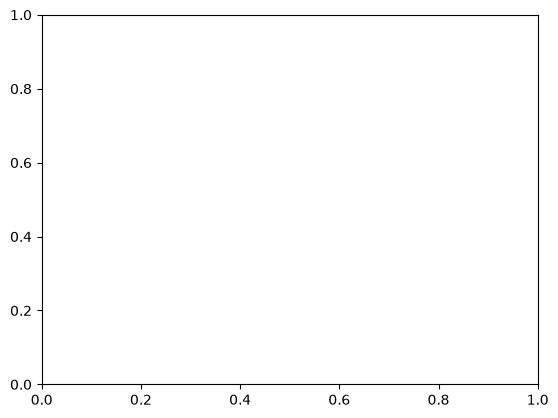

In [187]:
fig, ax = plt.subplots()
for i, theta_true in enumerate(np.linspace(0, np.pi / 2, n_values)):
    rho_hat = \
        # <CORRECTION>
        (I_dir * np.cos(theta_true) + I_dif) / (I_dir * np.cos(theta) + I_dif) * rho
        # </CORRECTION>
    label = r'$\theta$' + f'={theta_true * 180 / np.pi:.0f}deg' if i % 2 == 0 else None
    ax.plot(lam, rho_hat, color=colors[i], label=label)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.legend(fontsize=int(0.75*fontsize))
ax.grid()
plt.show()